# Data Analysis Notebook

## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import sys
import colorsys


from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore

## Import Paths

In [3]:
from pathlib import Path
from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
#print(PROJECT_ROOT)



## Import Functions

In [4]:
from analysis.train_data.yolo.cv_yolo_full_eda import run_full_cv_yolo_eda


In [5]:
# import importlib
# import analysis.train_data.yolo.cv_yolo_full_eda as eda

# importlib.reload(eda)


In [6]:
# df, summary_df, eda_text = run_full_cv_yolo_eda(save_csv=True)
# df


## Load the Data

In [7]:
yolo_train_data_csv_path = PROJECT_ROOT /"src"/ "analysis"/"train_data"/"yolo"/"cv_yolo_full_analysis.csv"

df_complete = pd.read_csv(yolo_train_data_csv_path)
print("Head of the dataset:")
print(df_complete.head())
print("\nColumns of the dataset:")
print(df_complete.columns)

Head of the dataset:
                                           filename  \
0   02657761cacdda99-scrapped_resumes-architect.jpg   
1   02657761cacdda99-scrapped_resumes-architect.jpg   
2  0287439839da10d2-scrapped_resumes-accountant.jpg   
3  0287439839da10d2-scrapped_resumes-accountant.jpg   
4  028cd00be9bb156d-scrapped_resumes-accountant.jpg   

                                                path   width  height  \
0  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
1  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
3  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   768.0  1087.0   

   num_pixels width_height  aspect_ratio  colorfulness  color_variation  \
0   2965504.0    1448x2048      0.707031     30.761051         0.194928   
1   2965504.0    1448x2048      0.707031     30.761051         0.

## Variáveis
#####  aspect_ratio = width / height:
* < 1 -> imagem mais alta que larga (formato típico de página A4)
* ≈ 0.7 -> muito comum em CVs digitalizados
* > 1 -> imagem horizontal (raro em CVs)

#####  colorfulness (quão “colorida” é a imagem):
* < 10 -> quase preto-e-branco
* 10 – 30 -> documento simples
* > 30 -> cores fortes / gráficos

#####  color_variation (desvio padrão médio dos canais RGB (0–1)):
* < 0.1 -> muito uniforme
* 0.1 – 0.25 -> algumas cores 
* > 0.3 -> muitos cores

##### x_center_mean e y_center_mean são:
A posição média dos objetos(bounding boxes) detetados no CV, em coordenadas normalizadas do formato YOLO. Ex.: y_center = 0.2 -> objeto perto do topo

## 1. Yolo EDA

### 1.1 Explore the Data

#### 1.1.1 Remover casos have_to_remove = True

In [8]:
df_complete = df_complete.drop_duplicates(subset="filename")
df_complete.describe

<bound method NDFrame.describe of                                                filename  \
0       02657761cacdda99-scrapped_resumes-architect.jpg   
2      0287439839da10d2-scrapped_resumes-accountant.jpg   
4      028cd00be9bb156d-scrapped_resumes-accountant.jpg   
6     035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg   
8      0452d98376727179-scrapped_resumes-accountant.jpg   
...                                                 ...   
3491     97_jpg.rf.77c498d3c97ad821d62ab5f1bf7492c7.jpg   
3492     98_jpg.rf.bce63a9765af54345e5f401123cd4058.jpg   
3493     99_jpg.rf.ac43cf7a7db01207af24e74dab6f0440.jpg   
3494              Image_42-bing_images-arts_resumes.jpg   
3495              Image_42-bing_images-arts_resumes.png   

                                                   path   width  height  \
0     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4     C:\Users\danie\Desktop\lab

In [9]:
df_remove = df_complete[df_complete["have_to_remove"] == True].copy()
df_yolo = df_complete[df_complete["have_to_remove"] == False].copy()
df_yolo = df_yolo.drop_duplicates(subset="filename")


In [10]:
len(df_remove)

116

In [11]:
df_yolo.head()

,filename,path,width,height,num_pixels,width_height,aspect_ratio,colorfulness,color_variation,mean_red,...,has_labels,have_to_remove,number_text_block,number_photo,number_skill_table,x_center_mean,y_center_mean,in_text_photo_dataset,in_skill_table_dataset,has_any_object
0,02657761cacdda99-scrapped_resumes-architect.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1448.0,2048.0,2965504.0,1448x2048,0.707031,30.761051,0.194928,239.67635,...,True,False,9,1,0,0.316264,0.370093,True,True,True
2,0287439839da10d2-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,600.0,730.0,438000.0,600x730,0.821918,13.419292,0.191884,236.84930,...,True,False,6,0,0,0.434028,0.381507,True,True,True
4,028cd00be9bb156d-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,768.0,1087.0,834816.0,768x1087,0.706532,36.614601,0.177965,242.96956,...,True,False,6,0,9,0.479427,0.483471,True,True,True
6,035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1200.0,1714.0,2056800.0,1200x1714,0.700117,7.853670,0.201864,238.44190,...,True,False,7,1,0,0.385677,0.475022,True,True,True
8,0452d98376727179-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,544.0,769.0,418336.0,544x769,0.707412,39.265636,0.368994,169.45143,...,True,False,7,1,6,0.293658,0.393786,True,True,True


#### 1.1.2 Dataset apenas para cada tipo de deteção:

In [12]:
df_skill_table = df_yolo[df_yolo["in_skill_table_dataset"] == True].copy()

df_text_photo = df_yolo[df_yolo["in_text_photo_dataset"] == True].copy()


#### 1.1.7 Dividing categorical and numerical variables

In [13]:
numeric_cols_yolo = df_yolo.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_yolo = df_yolo.select_dtypes(include=['object']).columns.tolist()

numeric_cols_yolo, categorical_cols_yolo

(['width',
  'height',
  'num_pixels',
  'aspect_ratio',
  'colorfulness',
  'color_variation',
  'mean_red',
  'mean_green',
  'mean_blue',
  'std_red',
  'std_green',
  'std_blue',
  'mean_hue',
  'mean_saturation',
  'mean_value',
  'std_hue',
  'std_saturation',
  'std_value',
  'number_text_block',
  'number_photo',
  'number_skill_table',
  'x_center_mean',
  'y_center_mean'],
 ['filename', 'path', 'width_height', 'has_labels'])

### 1.2 Graphics

#### 1.2.1 Graph of the distribution of numerical variables

array([[<Axes: title={'center': 'width'}>,
        <Axes: title={'center': 'height'}>,
        <Axes: title={'center': 'num_pixels'}>,
        <Axes: title={'center': 'aspect_ratio'}>,
        <Axes: title={'center': 'colorfulness'}>],
       [<Axes: title={'center': 'color_variation'}>,
        <Axes: title={'center': 'mean_red'}>,
        <Axes: title={'center': 'mean_green'}>,
        <Axes: title={'center': 'mean_blue'}>,
        <Axes: title={'center': 'std_red'}>],
       [<Axes: title={'center': 'std_green'}>,
        <Axes: title={'center': 'std_blue'}>,
        <Axes: title={'center': 'mean_hue'}>,
        <Axes: title={'center': 'mean_saturation'}>,
        <Axes: title={'center': 'mean_value'}>],
       [<Axes: title={'center': 'std_hue'}>,
        <Axes: title={'center': 'std_saturation'}>,
        <Axes: title={'center': 'std_value'}>,
        <Axes: title={'center': 'number_text_block'}>,
        <Axes: title={'center': 'number_photo'}>],
       [<Axes: title={'center': '

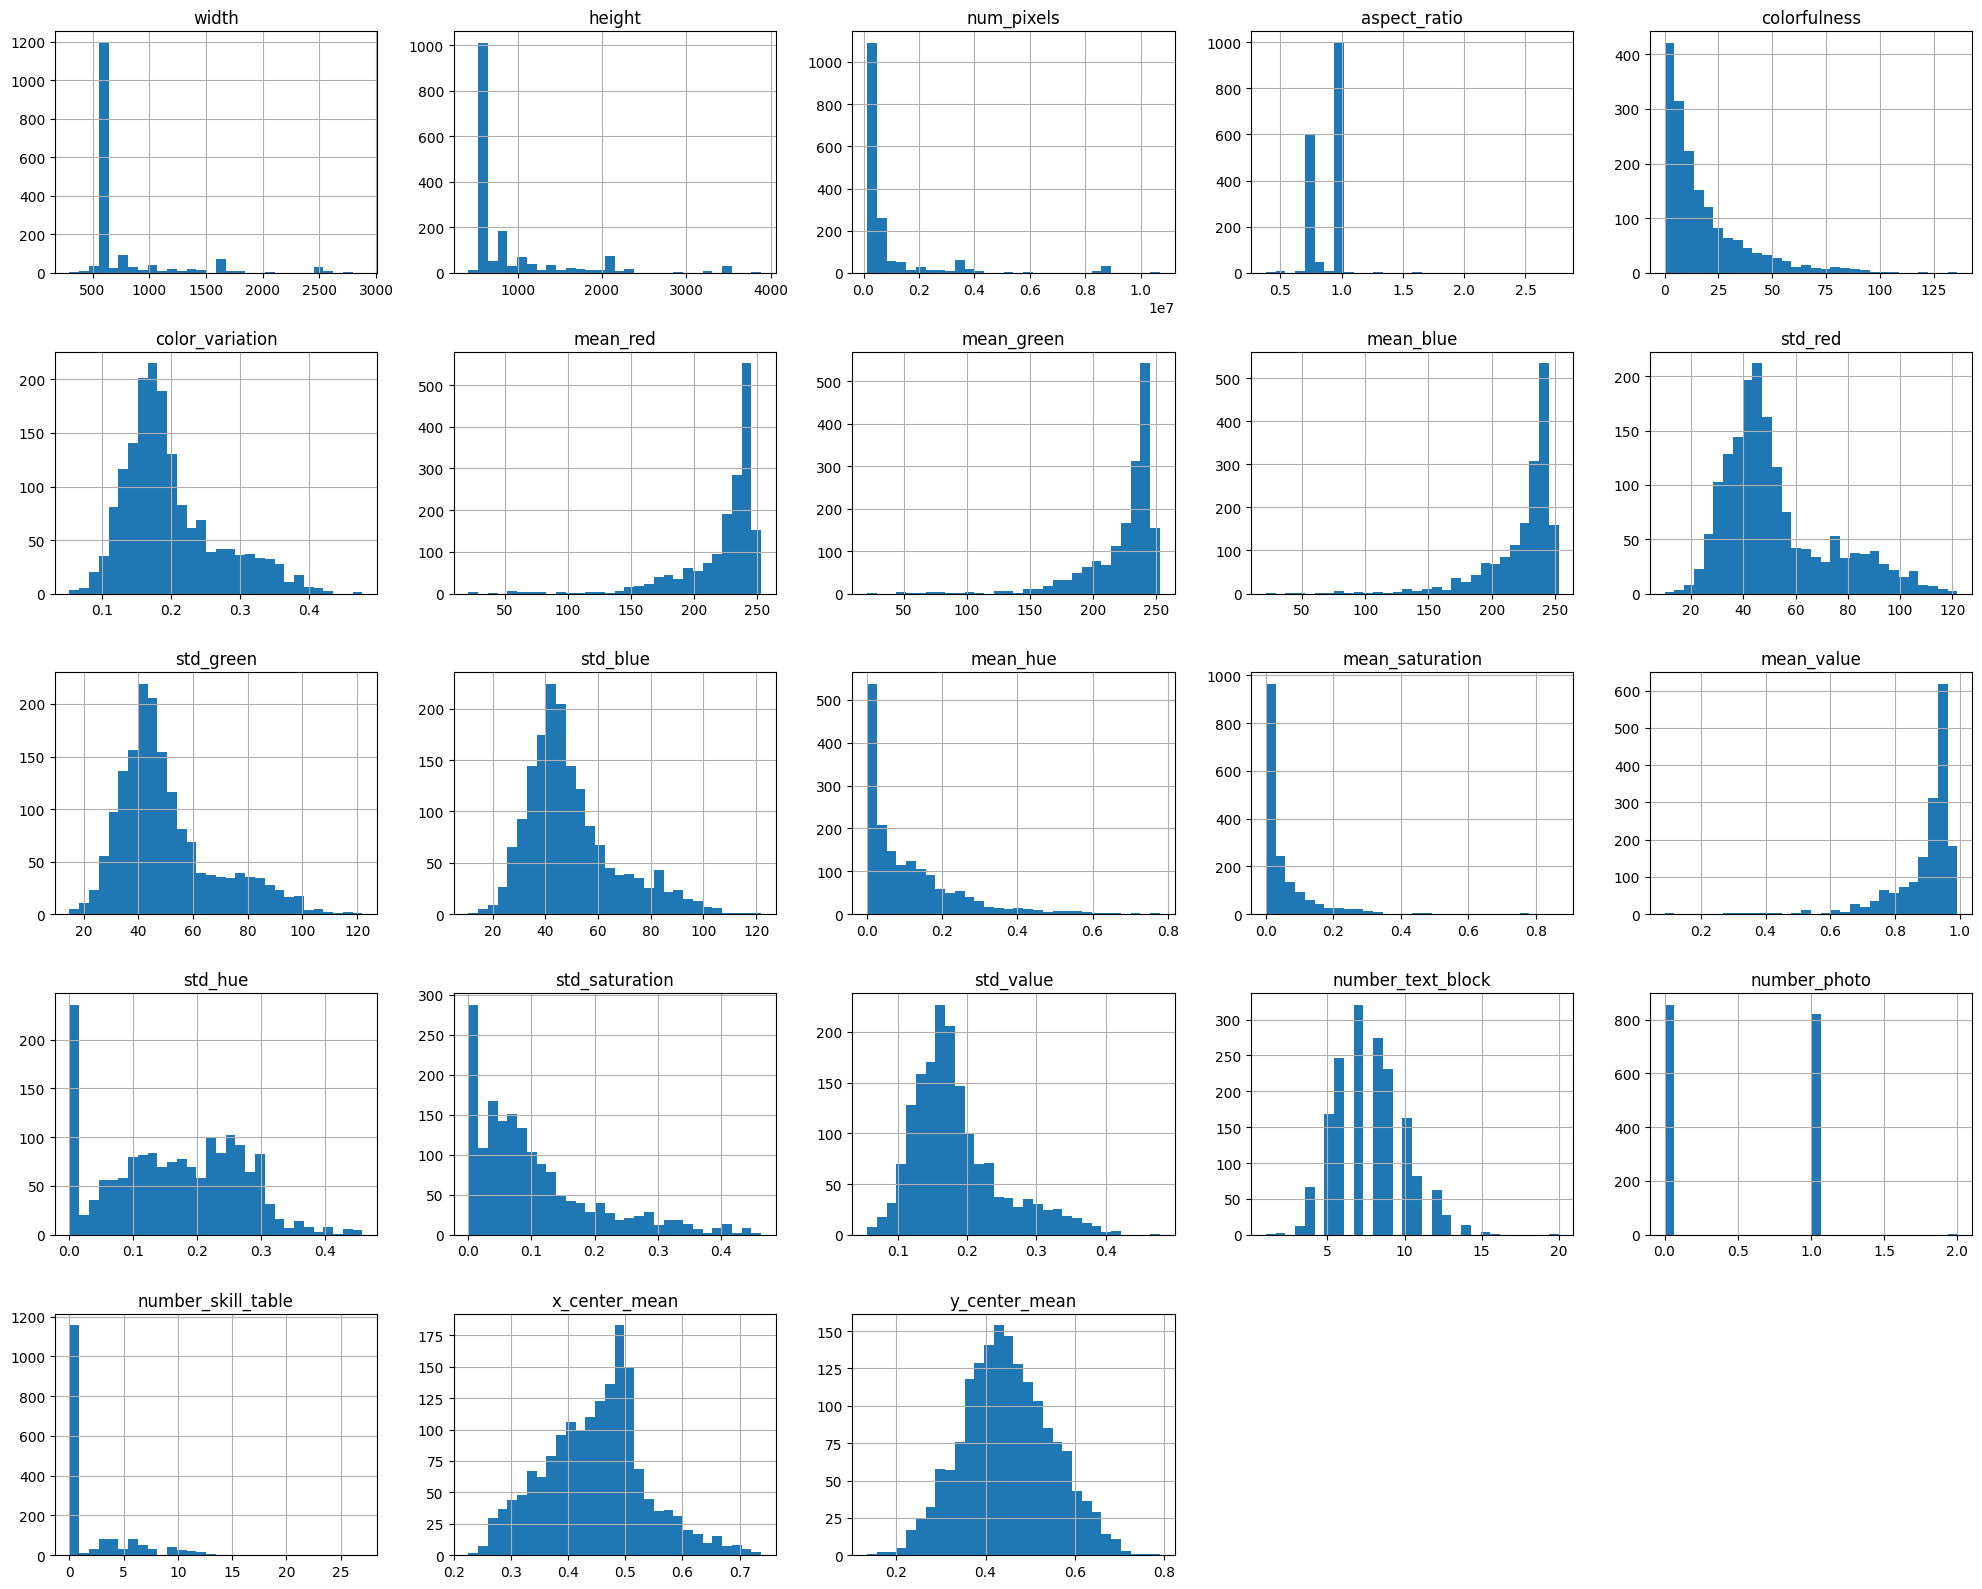

In [14]:
df_yolo[numeric_cols_yolo].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()

#### 1.2.2 Graphs of the bounding boxes

<Figure size 450x400 with 0 Axes>

<BarContainer object of 3 artists>

Text(0.5, 1.0, 'Total Bounding Boxes per Type')

Text(0, 0.5, 'Total Occurrences')

Text(0.5, 0, 'Bounding Box Type')

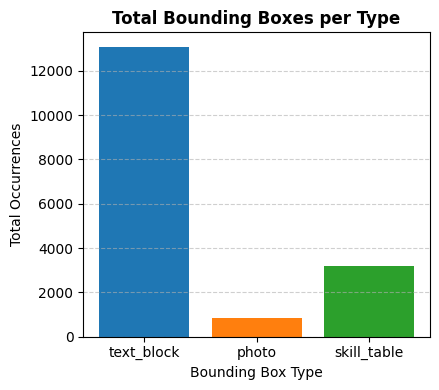

In [50]:
import matplotlib.pyplot as plt

# Select only the desired columns
cols = ["number_text_block", "number_photo", "number_skill_table"]

# Sum the total number of bounding boxes per type
totals = df_yolo[cols].sum()

# Labels curtos
labels = ["text_block", "photo", "skill_table"]

plt.figure(figsize=(4.5, 4))  # mais compacto

plt.bar(
    labels,
    totals.values,
    color=["tab:blue", "tab:orange", "tab:green"]
)

plt.title("Total Bounding Boxes per Type", weight="bold")  # título curto
plt.ylabel("Total Occurrences")
plt.xlabel("Bounding Box Type")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()



<Figure size 450x400 with 0 Axes>

<BarContainer object of 3 artists>

Text(0.5, 1.0, 'CVs with ≥1 Bounding Box per Type')

Text(0, 0.5, 'Number of CVs')

Text(0.5, 0, 'Bounding Box Type')

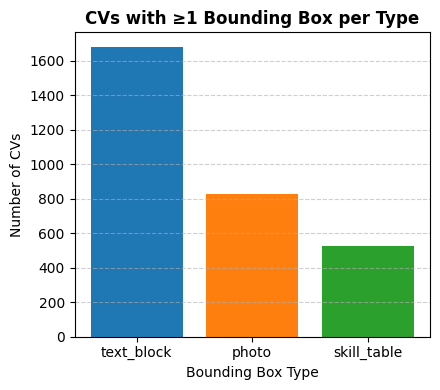

In [49]:
import matplotlib.pyplot as plt

cols = ["number_text_block", "number_photo", "number_skill_table"]

# Contar CVs com ≥1 ocorrência
cvs_with_element = (df_yolo[cols] >= 1).sum()

# Renomear labels para forma curta
labels = ["text_block", "photo", "skill_table"]

plt.figure(figsize=(4.5, 4))  # mais estreito

plt.bar(
    labels,
    cvs_with_element.values,
    color=["tab:blue", "tab:orange", "tab:green"]
)

plt.title("CVs with ≥1 Bounding Box per Type", weight="bold")  # título mais curto
plt.ylabel("Number of CVs")
plt.xlabel("Bounding Box Type")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()



(array([  1.,   3.,  12.,  67., 169., 246., 321., 275., 231., 163.,  82.,
         63.,  28.,  13.,   4.,   1.,   0.,   0.,   0.,   1.]),
 array([ 1.  ,  1.95,  2.9 ,  3.85,  4.8 ,  5.75,  6.7 ,  7.65,  8.6 ,
         9.55, 10.5 , 11.45, 12.4 , 13.35, 14.3 , 15.25, 16.2 , 17.15,
        18.1 , 19.05, 20.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: number_text_block')

Text(0.5, 0, 'Number of Occurrences per CV')

Text(0, 0.5, 'Frequency')

(array([856.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 820.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   4.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([1.166e+03, 3.000e+01, 1.660e+02, 3.300e+01, 8.300e+01, 8.700e+01,
        4.200e+01, 2.500e+01, 3.400e+01, 5.000e+00, 2.000e+00, 3.000e+00,
        1.000e+00, 2.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.  ,  1.35,  2.7 ,  4.05,  5.4 ,  6.75,  8.1 ,  9.45, 10.8 ,
        12.15, 13.5 , 14.85, 16.2 , 17.55, 18.9 , 20.25, 21.6 , 22.95,
        24.3 , 25.65, 27.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: number_skill_table')

Text(0.5, 0, 'Number of Occurrences per CV')

Text(0, 0.5, 'Frequency')

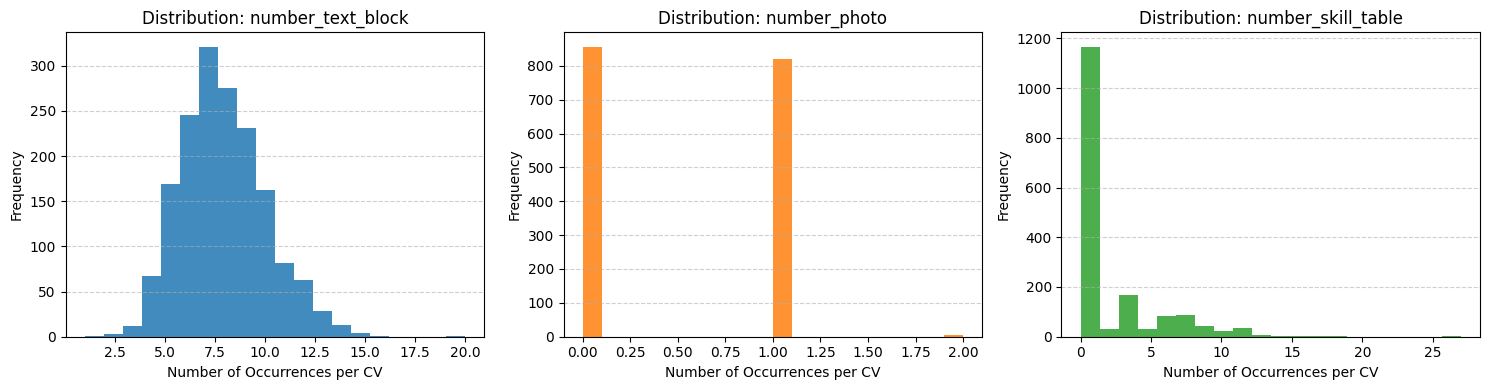

In [17]:
cols = [
    ("number_text_block", "tab:blue"),
    ("number_photo", "tab:orange"),
    ("number_skill_table", "tab:green"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.85)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Number of Occurrences per CV")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    

plt.tight_layout()
plt.show()


<Figure size 450x400 with 0 Axes>

C:\Users\danie\AppData\Local\Temp\ipykernel_21616\3902562198.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


([<matplotlib.axis.YTick at 0x28567451b10>,
 [Text(0, 0, '0'),
  Text(0, 2, '2'),
  Text(0, 4, '4'),
  Text(0, 6, '6'),
  Text(0, 8, '8'),
  Text(0, 10, '10'),
  Text(0, 12, '12'),
  Text(0, 14, '14'),
  Text(0, 16, '16'),
  Text(0, 18, '18'),
  Text(0, 20, '20'),
  Text(0, 22, '22'),
  Text(0, 24, '24'),
  Text(0, 26, '26'),
  Text(0, 28, '28')])

Text(0, 0.5, 'Number of Occurrences per CV')

Text(0.5, 1.0, 'Distribution of Bounding Boxes by Type')

Text(0.5, 0, 'Bounding Box Type')

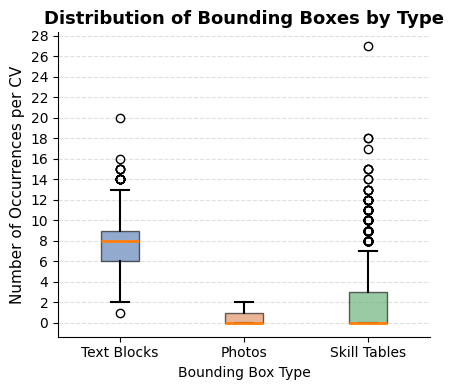

In [54]:
cols = ["number_text_block", "number_photo", "number_skill_table"]
data = [df_yolo[c] for c in cols]

plt.figure(figsize=(4.5, 4))

box = plt.boxplot(
    data,
    labels=["Text Blocks", "Photos", "Skill Tables"],
    patch_artist=True,
    showfliers=True,
    medianprops=dict(linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
)

# Cores suaves
colors = ["#4C72B0", "#DD8452", "#55A868"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# ===== eixo Y com valores inteiros =====
y_max = int(max(df_yolo[cols].max()))
plt.yticks(np.arange(0, y_max + 2, 2))

# Estética geral
plt.ylabel("Number of Occurrences per CV", fontsize=11)
plt.title("Distribution of Bounding Boxes by Type", fontsize=13, weight="bold")
plt.xlabel("Bounding Box Type")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



#### 1.2.3 Correlation Matrix Numeric Values

In [19]:
def plot_numeric_correlations(
    df,
    cols=None,
    figsize=(6, 5),
    cmap="Blues",
    annot=True,
    vmin=-1,
    vmax=1,
    title="Correlation Matrix of Numeric Variables"
):
    """
    Plots a correlation heatmap for numeric variables in a DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataframe.
    cols : list[str] or None, optional
        List of columns to include. If None, all numeric columns are used.
    figsize : tuple, optional
        Figure size.
    cmap : str, optional
        Colormap for heatmap.
    annot : bool, optional
        Whether to display correlation values.
    vmin, vmax : float, optional
        Color scale limits.
    title : str, optional
        Plot title.
    """

    # Selecionar apenas colunas numéricas se não forem fornecidas
    if cols is None:
        data = df.select_dtypes(include="number")
    else:
        data = df[cols]

    # Calcular correlação
    corr = data.corr()

    # Criar figura
    plt.figure(figsize=figsize)
    sns.heatmap(
        corr,
        annot=annot,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    plt.title(title, fontsize=12, weight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()



def plot_yolo_numeric_correlations_final(
    df_yolo,
    numeric_cols_yolo,
    figsize=(12, 10),
    corr_threshold=0.98,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    title="Correlation Structure of YOLO Numeric Features"
):
    """
    Publication-ready correlation heatmap for YOLO numeric features.

    Features:
    - removes near-duplicate variables
    - lower-triangle display
    - numeric annotations inside cells
    - larger, readable layout
    """

    # --- selecionar dados numéricos ---
    data = df_yolo[numeric_cols_yolo].select_dtypes(include="number")

    # --- remover variáveis quase duplicadas ---
    corr_full = data.corr().abs()
    upper = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > corr_threshold)]
    data = data.drop(columns=to_drop)

    # --- nova correlação ---
    corr = data.corr()

    # --- máscara metade superior ---
    mask = np.triu(np.ones_like(corr, dtype=bool))

    # --- plot ---
    plt.figure(figsize=figsize)

    sns.heatmap(
        corr,
        mask=mask,
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        annot=annot,
        fmt=fmt,
        annot_kws={"size": 8},
        cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"}
    )

    plt.title(title, fontsize=15, weight="bold")
    plt.xticks(rotation=40, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)

    plt.tight_layout()
    plt.show()



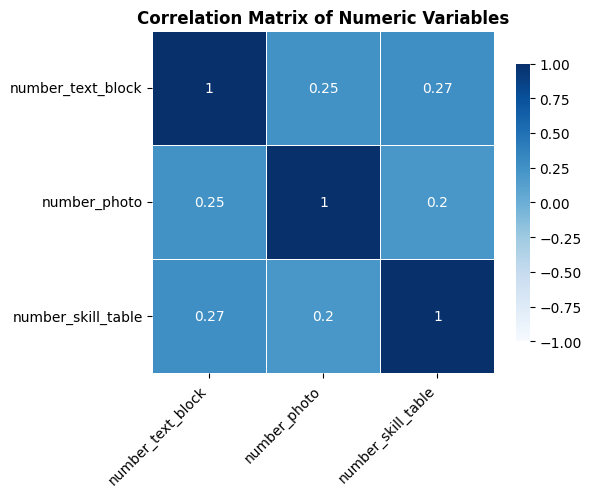

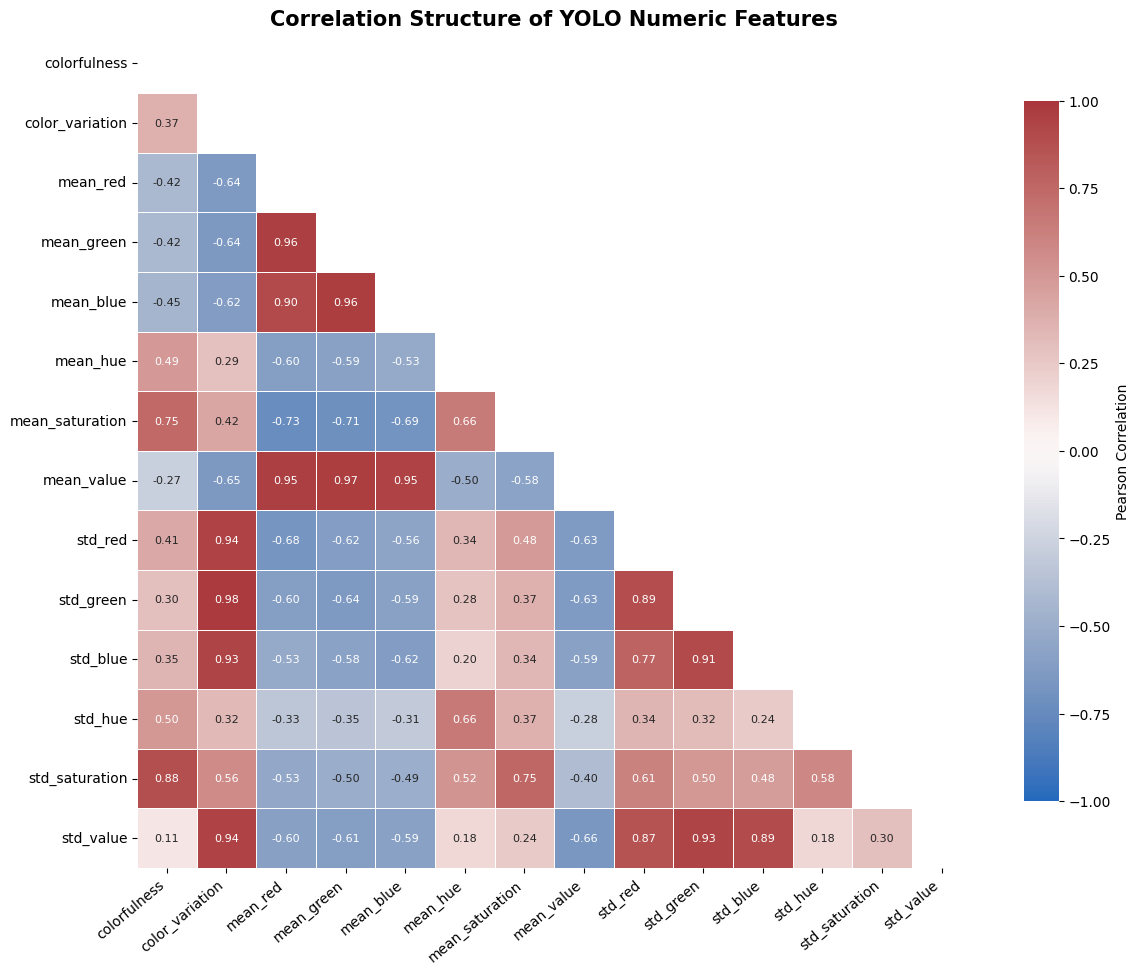

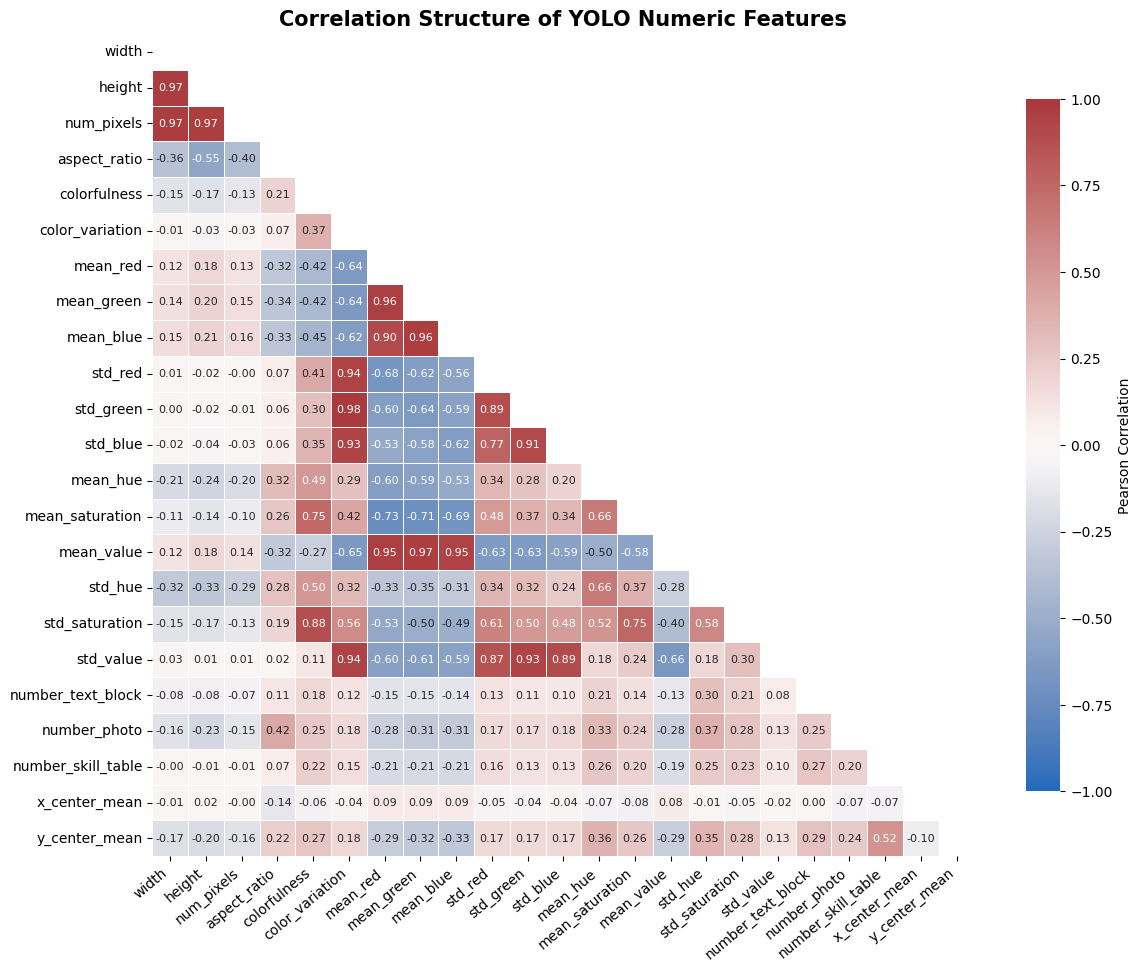

In [20]:
cols = ["number_text_block", "number_photo", "number_skill_table"]
color_cols = [
    "colorfulness", "color_variation",
    "mean_red", "mean_green", "mean_blue", "mean_hue", "mean_saturation", "mean_value",
    "std_red", "std_green", "std_blue","std_hue", "std_saturation", "std_value"]
plot_numeric_correlations(df_yolo, cols)

plot_yolo_numeric_correlations_final(df_yolo, color_cols)


plot_yolo_numeric_correlations_final(df_yolo, numeric_cols_yolo)





#### 1.2.4 Graphs of the colors

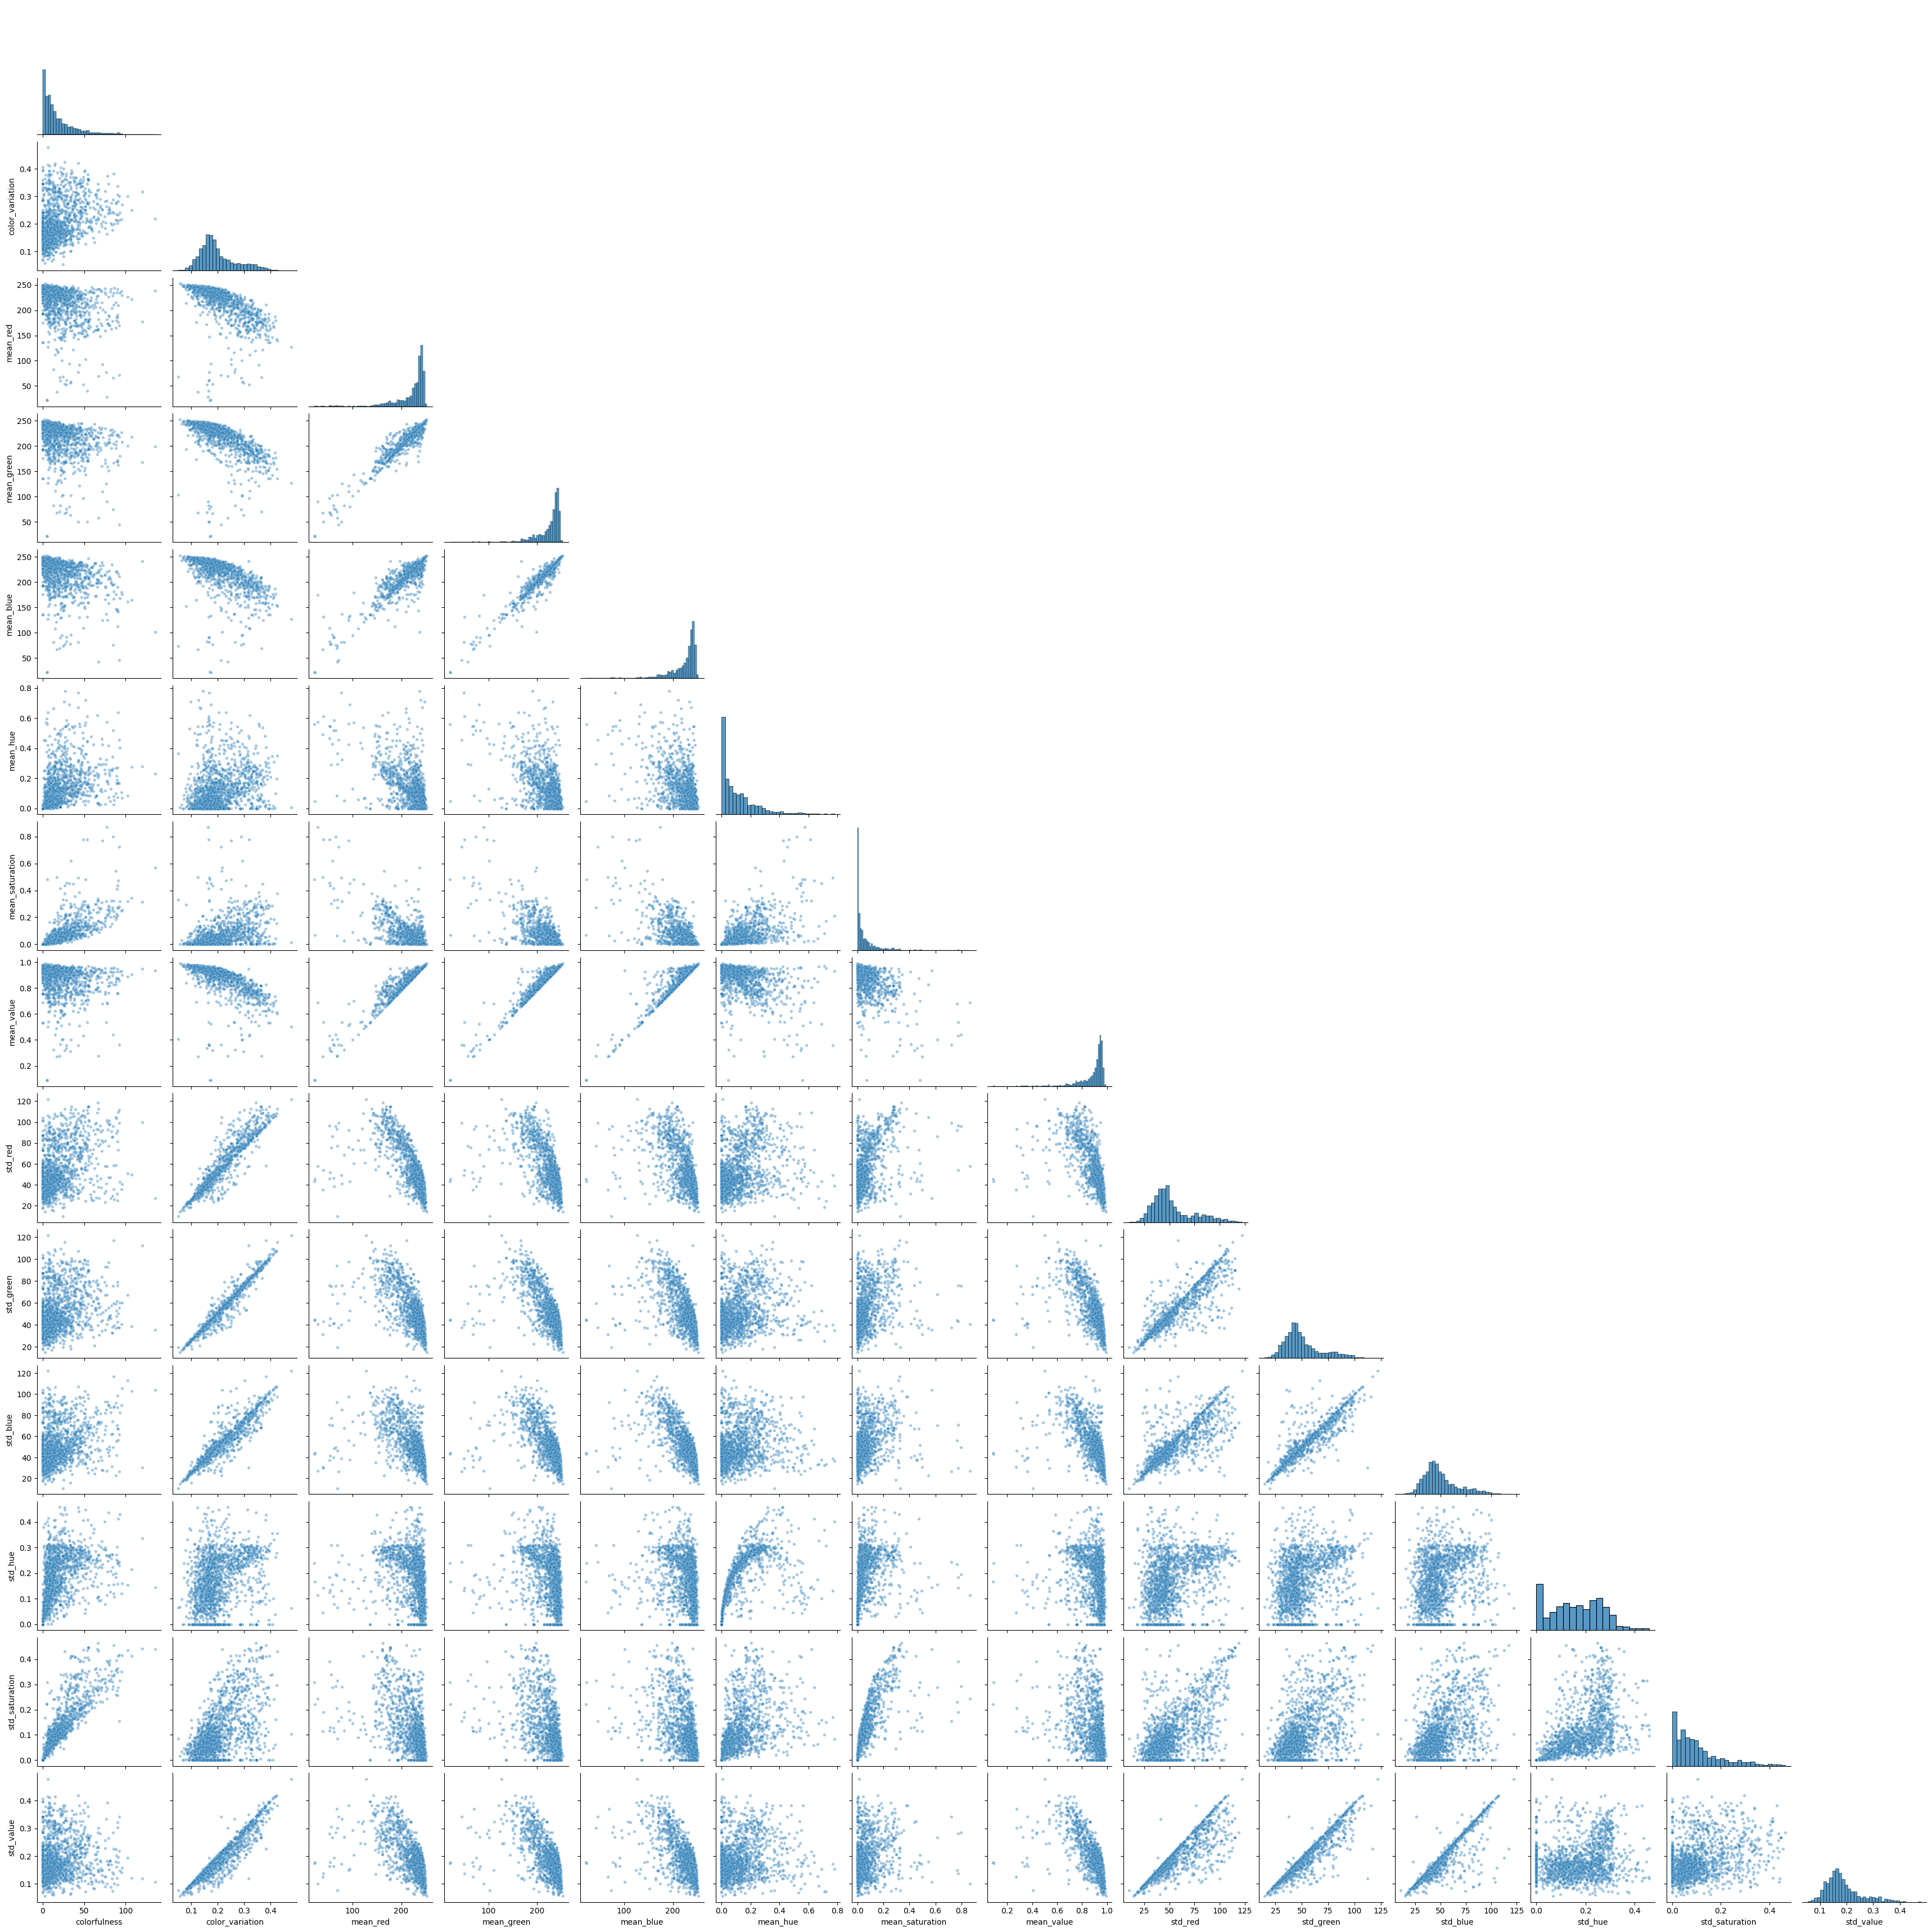

In [21]:
color_cols = [
    "colorfulness", "color_variation",
    "mean_red", "mean_green", "mean_blue", "mean_hue", "mean_saturation", "mean_value",
    "std_red", "std_green", "std_blue","std_hue", "std_saturation", "std_value"]

sns.pairplot(df_yolo[color_cols], corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.show()


<Axes: xlabel='colorfulness', ylabel='number_skill_table'>

Text(0.5, 1.0, 'Colorfulness vs Number of Skill Tables')

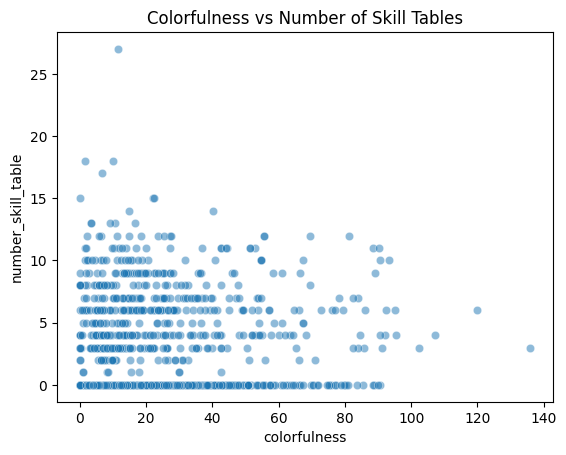

In [22]:
sns.scatterplot(
    data=df_yolo,
    x="colorfulness",
    y="number_skill_table",
    alpha=0.5
)
plt.title("Colorfulness vs Number of Skill Tables")
plt.show()


<Figure size 400x500 with 0 Axes>

<Axes: xlabel='has_photo', ylabel='colorfulness'>

Text(0.5, 1.0, 'Colorfulness Distribution by Photo Presence')

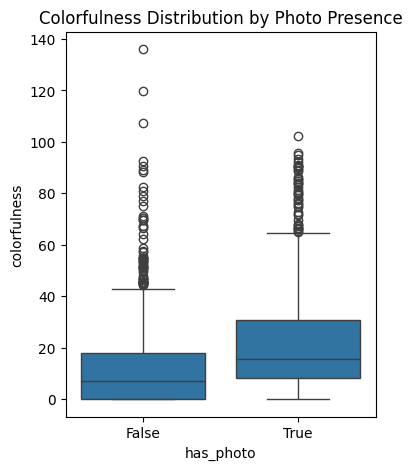

In [23]:
import seaborn as sns

df_yolo["has_photo"] = df_yolo["number_photo"] > 0
plt.figure(figsize=(4, 5))
sns.boxplot(data=df_yolo, x="has_photo", y="colorfulness")
plt.title("Colorfulness Distribution by Photo Presence")
plt.show()


Text(0.5, 1.0, 'Colorfulness Distribution by Photo Presence')

Text(0.5, 0, 'Colorfulness')

Text(0, 0.5, 'Number of CVs')

Text(0.5, 1.0, 'Color Variation Distribution by Photo Presence')

Text(0.5, 0, 'Color Variation')

Text(0, 0.5, 'Number of CVs')

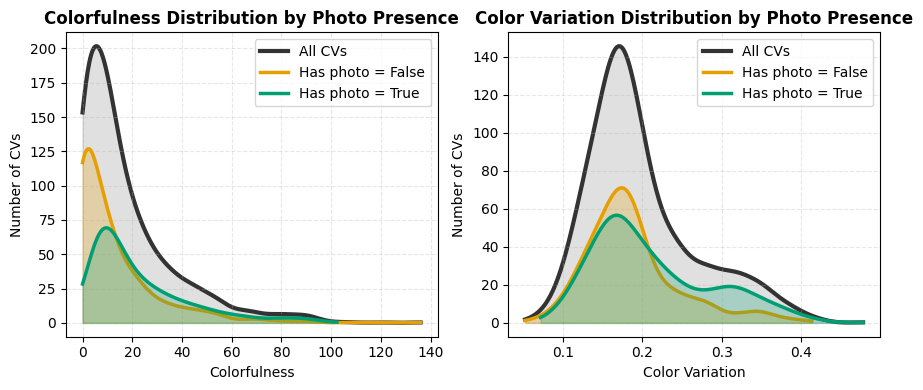

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


def kde_count_curve(ax, data, color, label, bins=40, linewidth=2.5, alpha_fill=0.25, zorder=2):
    """Plot KDE scaled to represent counts instead of density."""
    
    data = np.asarray(data.dropna())
    if len(data) < 2:
        return

    kde = gaussian_kde(data)

    x = np.linspace(data.min(), data.max(), 400)
    density = kde(x)

    # converter densidade → contagem
    bin_width = (data.max() - data.min()) / bins
    counts = density * len(data) * bin_width

    ax.plot(x, counts, color=color, linewidth=linewidth, label=label, zorder=zorder)
    ax.fill_between(x, counts, color=color, alpha=alpha_fill, zorder=zorder)


fig, axes = plt.subplots(1, 2, figsize=(9, 4))

palette = {False: "#E69F00", True: "#009E73"}  # laranja / verde
global_color = "#333333"  # cinza escuro/preto suave


# ===============================
# COLORFULNESS
# ===============================
# curva global primeiro (fundo)
kde_count_curve(
    axes[0],
    df_yolo["colorfulness"],
    global_color,
    "All CVs",
    linewidth=3,
    alpha_fill=0.15,
    zorder=1,
)

# curvas por classe
for has_photo, color in palette.items():
    subset = df_yolo[df_yolo["has_photo"] == has_photo]["colorfulness"]
    kde_count_curve(axes[0], subset, color, f"Has photo = {has_photo}")

axes[0].set_title("Colorfulness Distribution by Photo Presence", weight = "bold")
axes[0].set_xlabel("Colorfulness")
axes[0].set_ylabel("Number of CVs")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.3)


# ===============================
# COLOR VARIATION
# ===============================
kde_count_curve(
    axes[1],
    df_yolo["color_variation"],
    global_color,
    "All CVs",
    linewidth=3,
    alpha_fill=0.15,
    zorder=1,
)

for has_photo, color in palette.items():
    subset = df_yolo[df_yolo["has_photo"] == has_photo]["color_variation"]
    kde_count_curve(axes[1], subset, color, f"Has photo = {has_photo}")

axes[1].set_title("Color Variation Distribution by Photo Presence", weight = "bold")
axes[1].set_xlabel("Color Variation")
axes[1].set_ylabel("Number of CVs")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


<Figure size 600x500 with 0 Axes>

Text(0.5, 0, 'Width (pixels)')

Text(0, 0.5, 'Height (pixels)')

Text(0.5, 1.0, 'Image Geometry: Width vs Height Colored by Aspect Ratio')

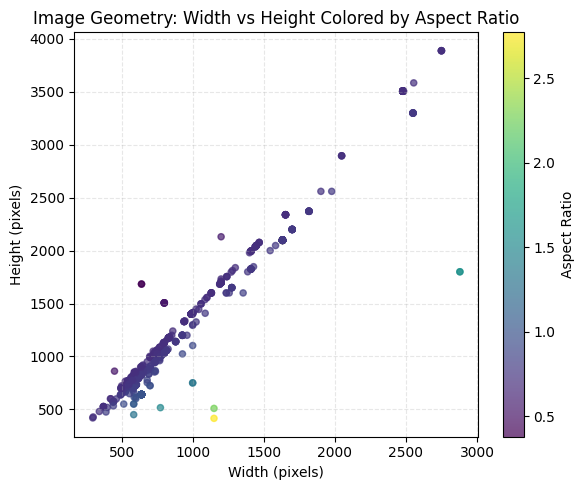

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sc = plt.scatter(
    df_yolo["width"],
    df_yolo["height"],
    c=df_yolo["aspect_ratio"],
    cmap="viridis",
    s=20,
    alpha=0.7
)

plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Geometry: Width vs Height Colored by Aspect Ratio", weight = "bold")

cb = plt.colorbar(sc)
cb.set_label("Aspect Ratio")

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


(array([  3.,   2.,   4.,   4.,   6.,   1.,   5.,   1.,   5.,   3.,  16.,
         24.,  44.,  63.,  64.,  88., 117., 241., 562., 427.]),
 array([ 21.108418 ,  32.7094461,  44.3104742,  55.9115023,  67.5125304,
         79.1135585,  90.7145866, 102.3156147, 113.9166428, 125.5176709,
        137.118699 , 148.7197271, 160.3207552, 171.9217833, 183.5228114,
        195.1238395, 206.7248676, 218.3258957, 229.9269238, 241.5279519,
        253.12898  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_red')

Text(0.5, 0, 'Mean Intensity Value')

Text(0, 0.5, 'Frequency')

(array([  2.,   0.,   3.,   3.,   5.,   4.,   3.,   3.,   2.,  10.,   4.,
         18.,  36.,  45.,  88., 100., 109., 237., 584., 424.]),
 array([ 20.914013  ,  32.51867935,  44.1233457 ,  55.72801205,
         67.3326784 ,  78.93734475,  90.5420111 , 102.14667745,
        113.7513438 , 125.35601015, 136.9606765 , 148.56534285,
        160.1700092 , 171.77467555, 183.3793419 , 194.98400825,
        206.5886746 , 218.19334095, 229.7980073 , 241.40267365,
        253.00734   ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  2.,   1.,   1.,   1.,   5.,   4.,   4.,   3.,   3.,  12.,   9.,
         22.,  27.,  43.,  81., 102., 128., 232., 574., 426.]),
 array([ 21.450272 ,  33.0262019,  44.6021318,  56.1780617,  67.7539916,
         79.3299215,  90.9058514, 102.4817813, 114.0577112, 125.6336411,
        137.209571 , 148.7855009, 160.3614308, 171.9373607, 183.5132906,
        195.0892205, 206.6651504, 218.2410803, 229.8170102, 241.3929401,
        252.96887  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_blue')

Text(0.5, 0, 'Mean Intensity Value')

Text(0, 0.5, 'Frequency')

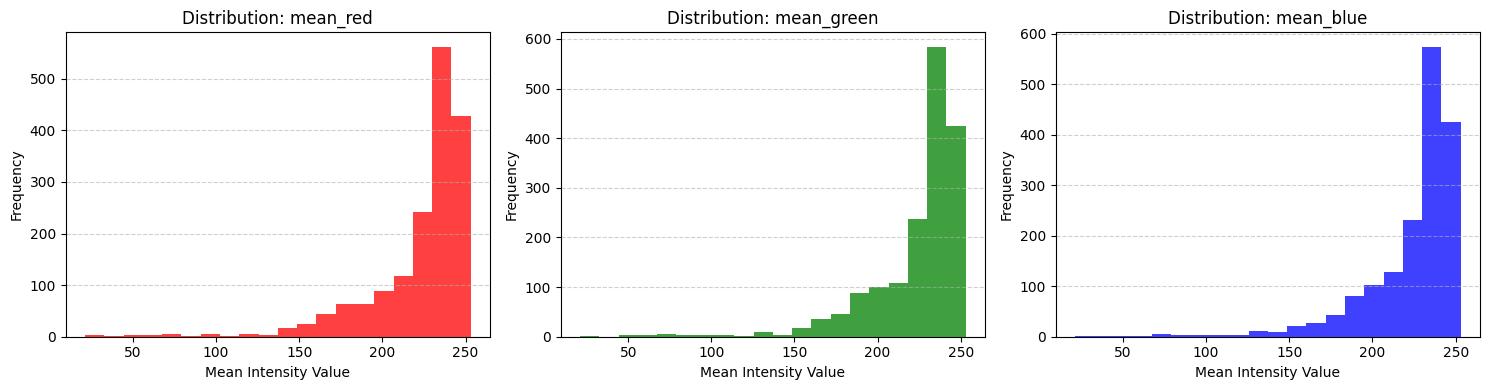

In [24]:
cols = [
    ("mean_red", "red"),
    ("mean_green", "green"),
    ("mean_blue", "blue"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.75)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Mean Intensity Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


<Figure size 400x500 with 0 Axes>

C:\Users\danie\AppData\Local\Temp\ipykernel_21616\2847692362.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


([<matplotlib.axis.YTick at 0x28565f41550>,
 [Text(0, 0, '0'),
  Text(0, 25, '25'),
  Text(0, 50, '50'),
  Text(0, 75, '75'),
  Text(0, 100, '100'),
  Text(0, 125, '125'),
  Text(0, 150, '150'),
  Text(0, 175, '175'),
  Text(0, 200, '200'),
  Text(0, 225, '225'),
  Text(0, 250, '250')])

(0.0, 255.0)

Text(0, 0.5, 'Mean Pixel Intensity')

Text(0.5, 1.0, 'Distribution of Mean RGB Intensities')

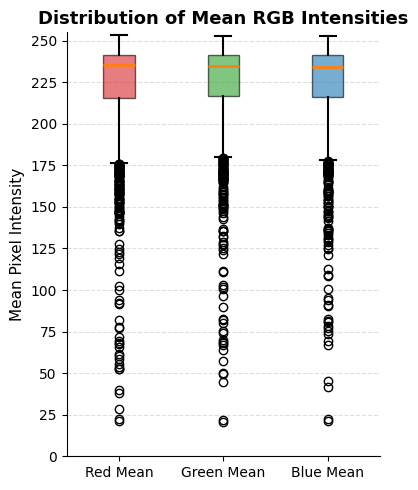

In [42]:
cols = ["mean_red", "mean_green", "mean_blue"]
data = [df_yolo[c] for c in cols]

plt.figure(figsize=(4, 5))

box = plt.boxplot(
    data,
    labels=["Red Mean", "Green Mean", "Blue Mean"],
    patch_artist=True,
    showfliers=True,
    medianprops=dict(linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
)

# Cores RGB suaves
colors = ["#D62728", "#2CA02C", "#1F77B4"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# ===== eixo Y em intensidade RGB =====
plt.yticks(np.arange(0, 256, 25))
plt.ylim(0, 255)

# Estética geral
plt.ylabel("Mean Pixel Intensity", fontsize=11)
plt.title("Distribution of Mean RGB Intensities", fontsize=13, weight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


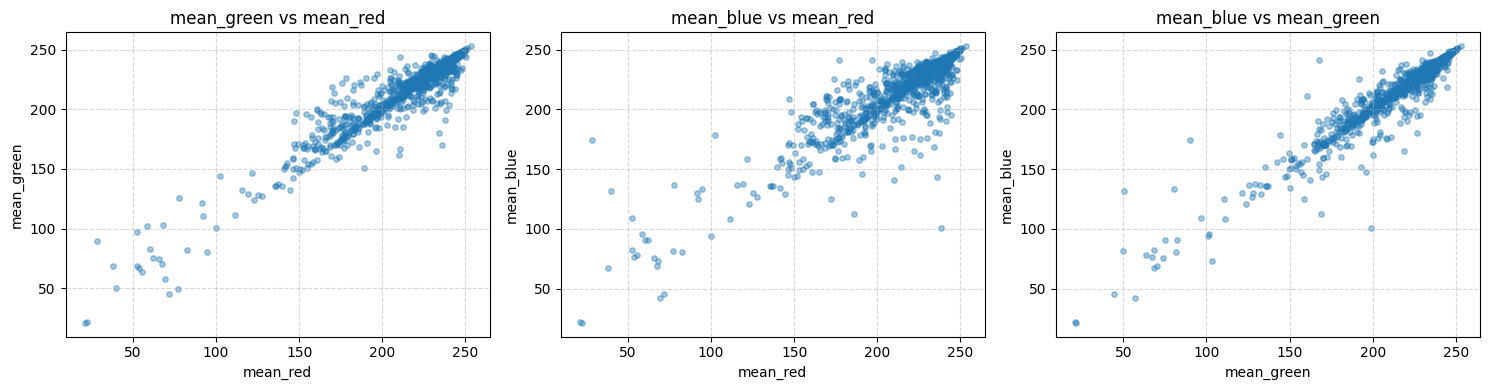

In [25]:
import matplotlib.pyplot as plt
import itertools


def plot_rgb_mean_correlations(df):
    """
    Scatter plots showing pairwise correlations between mean RGB channels.
    """

    pairs = list(itertools.combinations(["mean_red", "mean_green", "mean_blue"], 2))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (x_col, y_col) in zip(axes, pairs):
        ax.scatter(
            df[x_col],
            df[y_col],
            alpha=0.4,
            s=15
        )

        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{y_col} vs {x_col}", weight = "bold")
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

plot_rgb_mean_correlations(df_yolo)


C:\Users\danie\AppData\Local\Temp\ipykernel_21616\1728531471.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # deixa espaço à direita


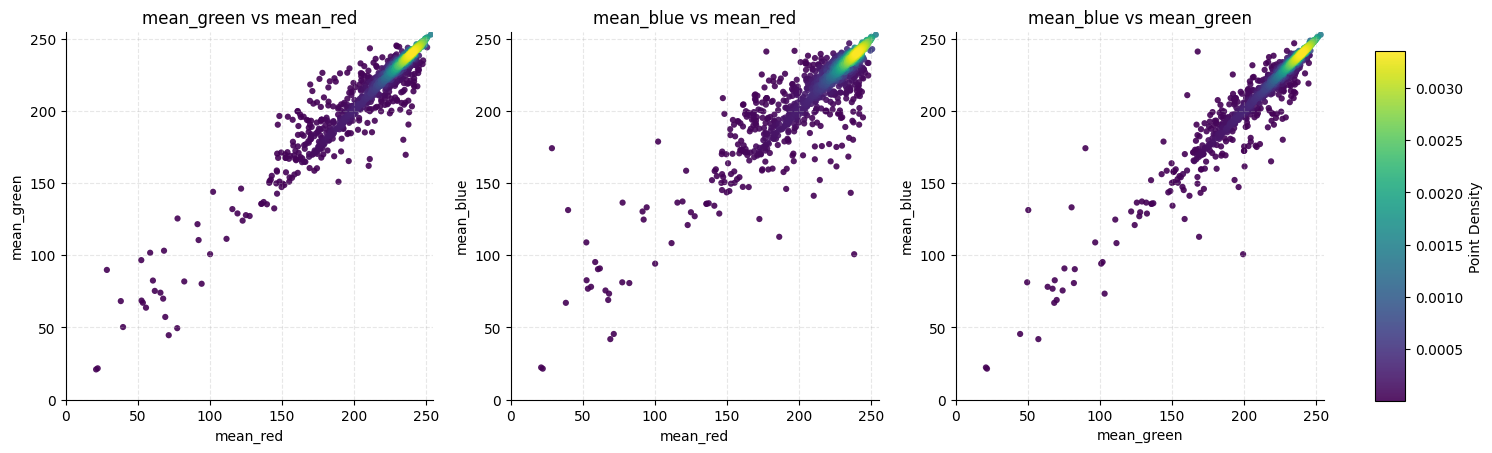

In [26]:
import matplotlib.pyplot as plt
import itertools
import numpy as np
from scipy.stats import gaussian_kde


def plot_rgb_mean_correlations_density(df):
    """
    Publication-quality RGB mean correlation plots
    with external colorbar and equal axes.
    """

    pairs = list(itertools.combinations(["mean_red", "mean_green", "mean_blue"], 2))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    scatters = []

    for ax, (x_col, y_col) in zip(axes, pairs):

        valid = df[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
        x = valid[x_col].values
        y = valid[y_col].values

        xy = np.vstack([x, y])
        z = gaussian_kde(xy)(xy)

        idx = z.argsort()
        x, y, z = x[idx], y[idx], z[idx]

        sc = ax.scatter(
            x, y,
            c=z,
            s=20,
            cmap="viridis",
            alpha=0.9,
            edgecolors="none"
        )

        scatters.append(sc)

        # eixos iguais
        lims = [0, 255]
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_aspect("equal", adjustable="box")

        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{y_col} vs {x_col}")

        ax.grid(True, linestyle="--", alpha=0.3)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # =============================
    # Colorbar externa (FIX)
    # =============================
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
    cbar = fig.colorbar(scatters[0], cax=cbar_ax)
    cbar.set_label("Point Density")

    plt.tight_layout(rect=[0, 0, 0.9, 1])  # deixa espaço à direita
    plt.show()


plot_rgb_mean_correlations_density(df_yolo)


(array([  2.,  10.,  46., 135., 203., 267., 301., 191.,  97.,  61.,  43.,
         73.,  50.,  56.,  56.,  32.,  25.,  19.,  11.,   2.]),
 array([  9.817783 ,  15.4264006,  21.0350182,  26.6436358,  32.2522534,
         37.860871 ,  43.4694886,  49.0781062,  54.6867238,  60.2953414,
         65.903959 ,  71.5125766,  77.1211942,  82.7298118,  88.3384294,
         93.947047 ,  99.5556646, 105.1642822, 110.7728998, 116.3815174,
        121.990135 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_red')

Text(0.5, 0, 'Standard Deviation of Intensity')

Text(0, 0.5, 'Frequency')

(array([  8.,  31., 100., 188., 259., 322., 220., 131.,  89.,  56.,  54.,
         54.,  56.,  41.,  28.,  28.,   6.,   5.,   2.,   2.]),
 array([ 14.853164 ,  20.2070018,  25.5608396,  30.9146774,  36.2685152,
         41.622353 ,  46.9761908,  52.3300286,  57.6838664,  63.0377042,
         68.391542 ,  73.7453798,  79.0992176,  84.4530554,  89.8068932,
         95.160731 , 100.5145688, 105.8684066, 111.2222444, 116.5760822,
        121.92992  ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  3.,  12.,  47., 137., 219., 323., 291., 180., 114.,  84.,  55.,
         57.,  55.,  35.,  33.,  18.,  10.,   4.,   1.,   2.]),
 array([ 10.739143  ,  16.29679185,  21.8544407 ,  27.41208955,
         32.9697384 ,  38.52738725,  44.0850361 ,  49.64268495,
         55.2003338 ,  60.75798265,  66.3156315 ,  71.87328035,
         77.4309292 ,  82.98857805,  88.5462269 ,  94.10387575,
         99.6615246 , 105.21917345, 110.7768223 , 116.33447115,
        121.89212   ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_blue')

Text(0.5, 0, 'Standard Deviation of Intensity')

Text(0, 0.5, 'Frequency')

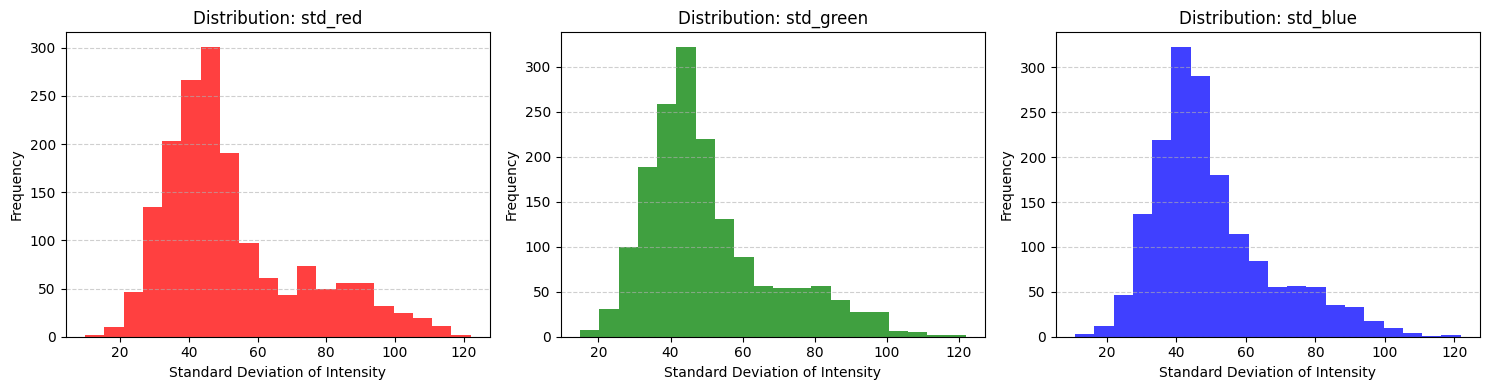

In [27]:
cols = [
    ("std_red", "red"),
    ("std_green", "green"),
    ("std_blue", "blue"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.75)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Standard Deviation of Intensity")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


(array([659., 233., 179., 164., 117.,  82.,  73.,  52.,  21.,  22.,  23.,
         13.,  10.,   9.,  10.,   4.,   2.,   3.,   2.,   2.]),
 array([0.        , 0.03895072, 0.07790143, 0.11685215, 0.15580286,
        0.19475358, 0.23370429, 0.27265501, 0.31160572, 0.35055644,
        0.38950715, 0.42845787, 0.46740858, 0.5063593 , 0.54531001,
        0.58426073, 0.62321144, 0.66216216, 0.70111287, 0.74006359,
        0.7790143 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_hue')

Text(0.5, 0, 'Mean HSV Value')

Text(0, 0.5, 'Frequency')

(array([1.114e+03, 2.300e+02, 1.240e+02, 6.900e+01, 4.200e+01, 3.100e+01,
        3.000e+01, 1.600e+01, 3.000e+00, 2.000e+00, 6.000e+00, 4.000e+00,
        1.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 3.000e+00,
        1.000e+00, 1.000e+00]),
 array([0.        , 0.04340745, 0.0868149 , 0.13022236, 0.17362981,
        0.21703726, 0.26044471, 0.30385216, 0.34725962, 0.39066707,
        0.43407452, 0.47748197, 0.52088942, 0.56429688, 0.60770433,
        0.65111178, 0.69451923, 0.73792668, 0.78133414, 0.82474159,
        0.86814904]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  2.,   0.,   0.,   0.,   4.,   5.,   4.,   4.,   1.,  11.,   1.,
         14.,  16.,  36.,  70.,  87., 106., 206., 613., 500.]),
 array([0.08803236, 0.13326827, 0.17850417, 0.22374008, 0.26897599,
        0.3142119 , 0.3594478 , 0.40468371, 0.44991962, 0.49515552,
        0.54039143, 0.58562734, 0.63086324, 0.67609915, 0.72133506,
        0.76657096, 0.81180687, 0.85704278, 0.90227869, 0.94751459,
        0.9927505 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_value')

Text(0.5, 0, 'Mean HSV Value')

Text(0, 0.5, 'Frequency')

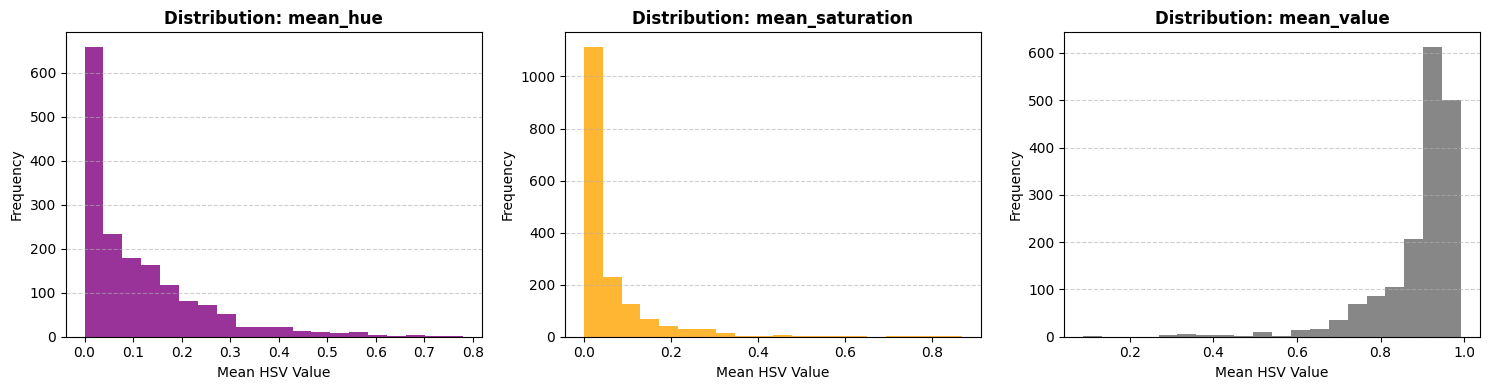

In [65]:
cols = [
    ("mean_hue", "purple"),   # Hue
    ("mean_saturation", "orange"),   # Saturation
    ("mean_value", "dimgray"),  # Value (brightness)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.8)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Mean HSV Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


(array([244.,  48.,  80.,  90., 122., 124., 107., 115., 101., 125., 123.,
        155., 107.,  71.,  20.,  17.,  10.,   9.,   5.,   7.]),
 array([0.        , 0.02292636, 0.04585271, 0.06877907, 0.09170542,
        0.11463178, 0.13755814, 0.16048449, 0.18341085, 0.2063372 ,
        0.22926356, 0.25218992, 0.27511627, 0.29804263, 0.32096898,
        0.34389534, 0.3668217 , 0.38974805, 0.41267441, 0.43560076,
        0.45852712]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_hue')

Text(0.5, 0, 'Standard Deviation in HSV Space')

Text(0, 0.5, 'Frequency')

(array([338., 225., 218., 208., 155., 114.,  65.,  65.,  56.,  39.,  30.,
         33.,  34.,  25.,  26.,  13.,   6.,  17.,   7.,   6.]),
 array([0.        , 0.02319579, 0.04639158, 0.06958737, 0.09278316,
        0.11597895, 0.13917475, 0.16237054, 0.18556633, 0.20876212,
        0.23195791, 0.2551537 , 0.27834949, 0.30154528, 0.32474107,
        0.34793686, 0.37113266, 0.39432845, 0.41752424, 0.44072003,
        0.46391582]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([ 16.,  40., 131., 226., 278., 325., 197., 119.,  95.,  49.,  43.,
         49.,  46.,  21.,  22.,  15.,   5.,   2.,   0.,   1.]),
 array([0.05563645, 0.076771  , 0.09790555, 0.1190401 , 0.14017465,
        0.1613092 , 0.18244375, 0.2035783 , 0.22471285, 0.2458474 ,
        0.26698195, 0.2881165 , 0.30925105, 0.3303856 , 0.35152015,
        0.3726547 , 0.39378925, 0.4149238 , 0.43605835, 0.4571929 ,
        0.47832745]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_value')

Text(0.5, 0, 'Standard Deviation in HSV Space')

Text(0, 0.5, 'Frequency')

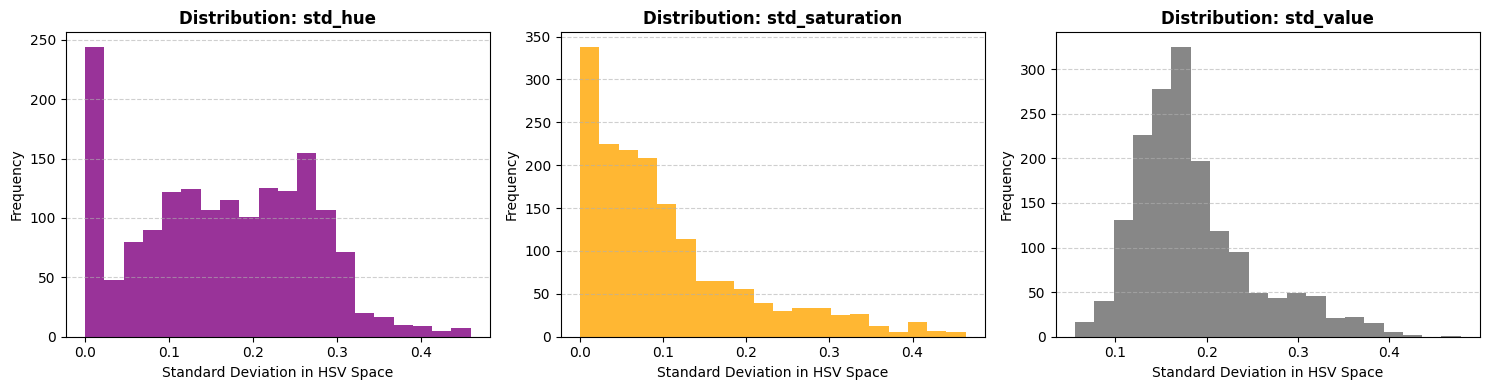

In [64]:
cols = [
    ("std_hue", "purple"),   # Hue variation
    ("std_saturation", "orange"),   # Saturation variation
    ("std_value", "dimgray"),  # Value (brightness) variation
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))


for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.8)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Standard Deviation in HSV Space")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


(array([486., 351., 229., 143., 104.,  78.,  63.,  49.,  42.,  34.,  23.,
         15.,  15.,   8.,  12.,   9.,  12.,   3.,   1.,   1.,   0.,   0.,
          1.,   0.,   1.]),
 array([  0.        ,   5.43990662,  10.87981323,  16.31971985,
         21.75962646,  27.19953308,  32.6394397 ,  38.07934631,
         43.51925293,  48.95915955,  54.39906616,  59.83897278,
         65.27887939,  70.71878601,  76.15869263,  81.59859924,
         87.03850586,  92.47841248,  97.91831909, 103.35822571,
        108.79813232, 114.23803894, 119.67794556, 125.11785217,
        130.55775879, 135.99766541]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: colorfulness')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

(array([  4.,   9.,  34.,  79., 134., 172., 259., 248., 167., 113.,  75.,
         73.,  43.,  56.,  42.,  44.,  34.,  39.,  23.,  18.,   7.,   6.,
          0.,   0.,   1.]),
 array([0.05245991, 0.06948938, 0.08651886, 0.10354834, 0.12057782,
        0.1376073 , 0.15463678, 0.17166625, 0.18869573, 0.20572521,
        0.22275469, 0.23978417, 0.25681364, 0.27384312, 0.2908726 ,
        0.30790208, 0.32493156, 0.34196103, 0.35899051, 0.37601999,
        0.39304947, 0.41007895, 0.42710843, 0.4441379 , 0.46116738,
        0.47819686]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: color_variation')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

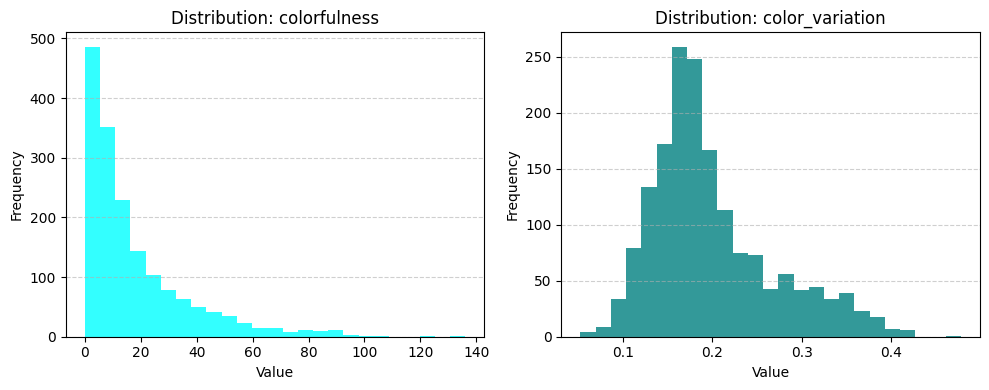

In [30]:
import matplotlib.pyplot as plt

cols = [
    ("colorfulness", "cyan"),
    ("color_variation", "teal"),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=25, color=color, alpha=0.8)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


#### 1.2.5 Graphs of the size

(array([9.000e+00, 1.900e+01, 1.620e+02, 1.083e+03, 9.600e+01, 3.100e+01,
        5.300e+01, 1.000e+01, 2.500e+01, 1.500e+01, 2.200e+01, 1.300e+01,
        6.500e+01, 1.800e+01, 8.000e+00, 1.000e+00, 4.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 4.000e+01, 0.000e+00, 4.000e+00,
        2.000e+00]),
 array([ 297.  ,  400.32,  503.64,  606.96,  710.28,  813.6 ,  916.92,
        1020.24, 1123.56, 1226.88, 1330.2 , 1433.52, 1536.84, 1640.16,
        1743.48, 1846.8 , 1950.12, 2053.44, 2156.76, 2260.08, 2363.4 ,
        2466.72, 2570.04, 2673.36, 2776.68, 2880.  ]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: width')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

(array([  17., 1020.,  118.,  133.,   76.,   42.,   10.,   44.,   19.,
          25.,   12.,   25.,   74.,    8.,    8.,    2.,    0.,    3.,
           0.,    0.,    7.,    0.,   33.,    0.,    4.]),
 array([ 415.  ,  553.96,  692.92,  831.88,  970.84, 1109.8 , 1248.76,
        1387.72, 1526.68, 1665.64, 1804.6 , 1943.56, 2082.52, 2221.48,
        2360.44, 2499.4 , 2638.36, 2777.32, 2916.28, 3055.24, 3194.2 ,
        3333.16, 3472.12, 3611.08, 3750.04, 3889.  ]),
 <BarContainer object of 25 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  2.,   8.,   0., 341., 315.,   7., 997.,   2.,   0.,   3.,   0.,
          1.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   1.]),
 array([0.38004751, 0.47568898, 0.57133045, 0.66697193, 0.7626134 ,
        0.85825487, 0.95389635, 1.04953782, 1.14517929, 1.24082077,
        1.33646224, 1.43210371, 1.52774519, 1.62338666, 1.71902813,
        1.8146696 , 1.91031108, 2.00595255, 2.10159402, 2.1972355 ,
        2.29287697, 2.38851844, 2.48415992, 2.57980139, 2.67544286,
        2.77108434]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: aspect_ratio')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

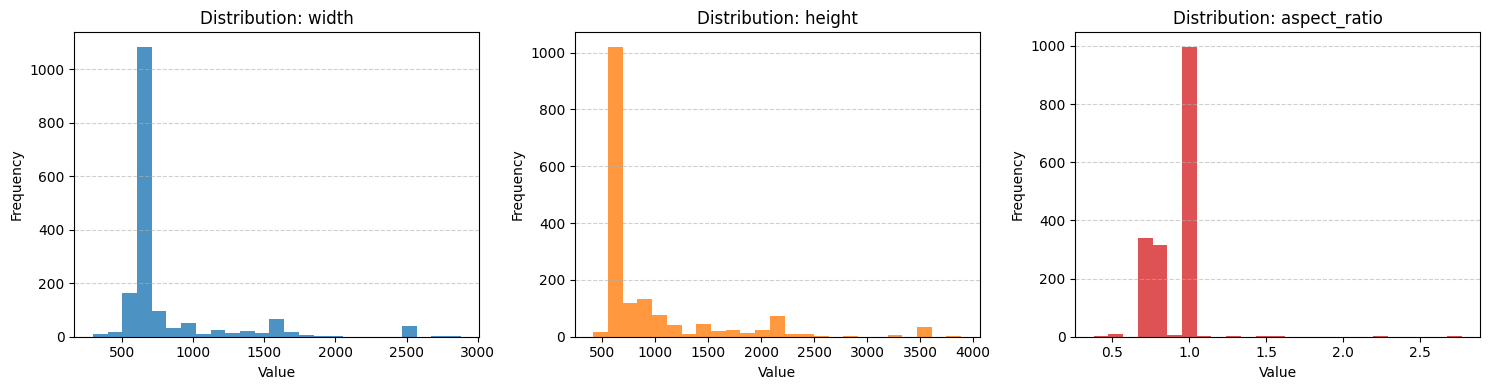

In [31]:
import matplotlib.pyplot as plt

cols = [
    ("width", "tab:blue"),
    ("height", "tab:orange"),
    #("num_pixels", "tab:green"),
    ("aspect_ratio", "tab:red"),
]

# fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=25, color=color, alpha=0.8)
    ax.set_title(f"Distribution: {col}", weight = "bold")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


<Figure size 500x400 with 0 Axes>

(array([  2.,   7.,   1.,   8., 600.,  48.,   7., 997.,   2.,   0.,   0.,
          3.,   0.,   0.,   1.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([0.38004751, 0.45974873, 0.53944996, 0.61915119, 0.69885242,
        0.77855364, 0.85825487, 0.9379561 , 1.01765733, 1.09735856,
        1.17705978, 1.25676101, 1.33646224, 1.41616347, 1.49586469,
        1.57556592, 1.65526715, 1.73496838, 1.8146696 , 1.89437083,
        1.97407206, 2.05377329, 2.13347452, 2.21317574, 2.29287697,
        2.3725782 , 2.45227943, 2.53198065, 2.61168188, 2.69138311,
        2.77108434]),
 <BarContainer object of 30 artists>)

(0.0, 1.8)

Text(0.5, 1.0, 'Aspect Ratio Distribution')

Text(0.5, 0, 'Aspect Ratio (width / height)')

Text(0, 0.5, 'Number of CVs')

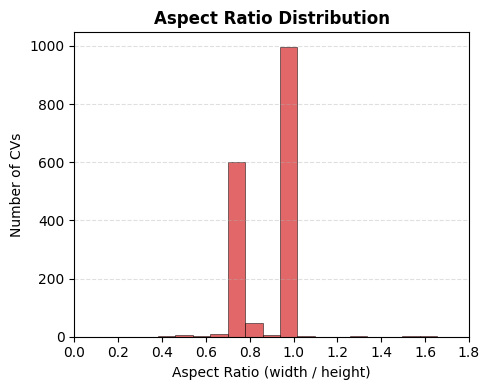

In [63]:
import matplotlib.pyplot as plt

aspect = df_yolo["aspect_ratio"].dropna()

plt.figure(figsize=(5, 4))

plt.hist(
    aspect,
    bins=30,
    color="#D62728",
    alpha=0.7,
    edgecolor="black",
    linewidth=0.5
)

# pequeno zoom apenas para melhor leitura
plt.xlim(0, 1.8)

plt.title("Aspect Ratio Distribution", weight = "bold")
plt.xlabel("Aspect Ratio (width / height)")
plt.ylabel("Number of CVs")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


Text(0.5, 0, 'Number of Pixels')

Text(0, 0.5, 'Number of CVs')

Text(0.5, 1.0, 'Distribution of Image Dimensions')

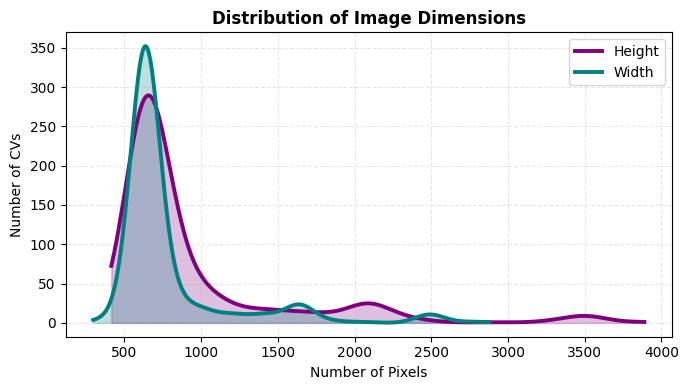

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


def kde_count_curve(ax, data, color, label, bins=40, lw=2.8, alpha=0.25):
    """KDE reescalado para representar contagem de CVs."""
    data = np.asarray(data.dropna())
    if len(data) < 2:
        return

    kde = gaussian_kde(data)

    x = np.linspace(data.min(), data.max(), 400)
    density = kde(x)

    # Converter densidade → número de CVs
    bin_width = (data.max() - data.min()) / bins
    counts = density * len(data) * bin_width

    ax.plot(x, counts, color=color, linewidth=lw, label=label)
    ax.fill_between(x, counts, color=color, alpha=alpha)


fig, ax = plt.subplots(figsize=(7, 4))

# Curvas
kde_count_curve(ax, df_yolo["height"], "purple", "Height")
kde_count_curve(ax, df_yolo["width"], "teal", "Width")

# Labels e estilo
ax.set_xlabel("Number of Pixels")
ax.set_ylabel("Number of CVs")
ax.set_title("Distribution of Image Dimensions", weight = "bold")

ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


<Figure size 600x600 with 0 Axes>

Text(0.5, 1.0, 'Spatial Distribution of Mean Bounding Box Centers')

Text(0.5, 0, 'x_center_mean (normalized image width)')

Text(0, 0.5, 'y_center_mean (normalized image height)')

(0.0, 1.0)

(1.0, 0.0)

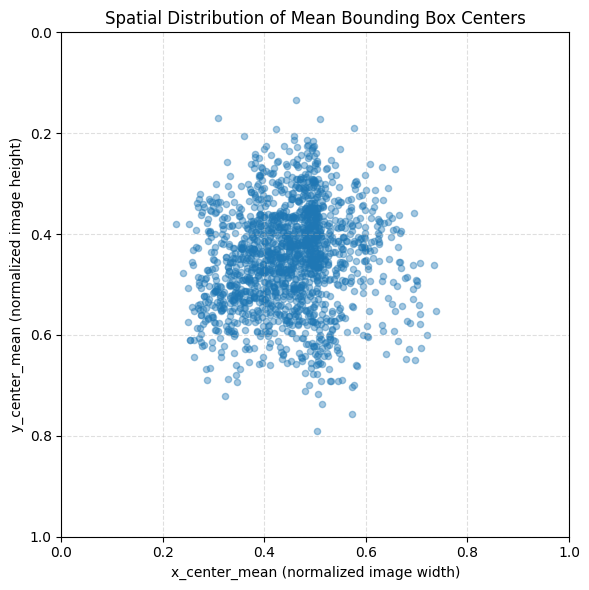

In [32]:
plt.figure(figsize=(6, 6))

plt.scatter(
    df_yolo["x_center_mean"],
    df_yolo["y_center_mean"],
    alpha=0.4,
    s=20
)

# Inverter eixo Y para simular coordenadas de imagem
plt.gca().invert_yaxis()

plt.title("Spatial Distribution of Mean Bounding Box Centers")
plt.xlabel("x_center_mean (normalized image width)")
plt.ylabel("y_center_mean (normalized image height)")

plt.xlim(0, 1)
plt.ylim(1, 0)  # mantém consistência visual após inversão
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


<Figure size 500x500 with 0 Axes>

Text(0.5, 1.0, 'Spatial Density of Bounding Box Centers')

Text(0.5, 0, 'Normalized X Position')

Text(0, 0.5, 'Normalized Y Position')

(0.0, 1.0)

(1.0, 0.0)

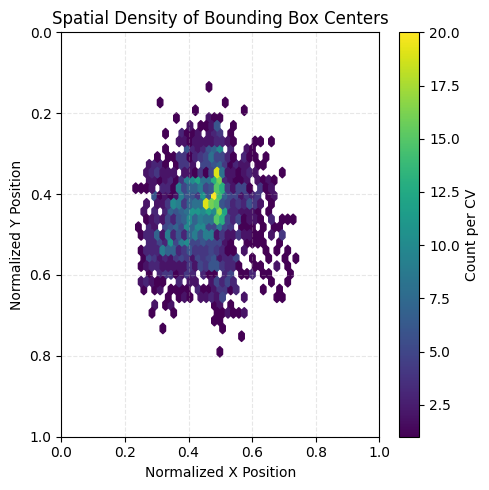

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

hb = plt.hexbin(
    df_yolo["x_center_mean"],
    df_yolo["y_center_mean"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.gca().invert_yaxis()

plt.title("Spatial Density of Bounding Box Centers")
plt.xlabel("Normalized X Position")
plt.ylabel("Normalized Y Position")

plt.xlim(0, 1)
plt.ylim(1, 0)

cb = plt.colorbar(hb)
cb.set_label("Count per CV")

plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()
